In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"]='4'
os.environ['HDF5_USE_FILE_LOCKING'] = 'FALSE'
import h5py
import sys
import cv2
import torch
import numpy as np
from tqdm import tqdm
from pathlib import Path
import matplotlib.pyplot as plt
from tqdm import tqdm
import traceback
from scipy.fft import fft
from scipy import signal
from scipy.signal import butter, filtfilt

In [42]:
# h5파일 key 확인
def explore_h5(f, prefix=''):
    for key in f.keys():
        obj = f[key]
        fullname = prefix + '/' + key
        print(f'{fullname}')
        if isinstance(obj, h5py.Dataset):
            print(f'  type  : Dataset')
            print(f'  shape : {obj.shape}')
            print(f'  dtype : {obj.dtype}')
            #print(f'  max_val : {np.max(obj)}')
            #print(f'  max : {np.max(obj)} , min : {np.min(obj)}')
        else:
            print(f'  type  : Group')
        if obj.attrs:
            for k, v in obj.attrs.items():
                print(f'  attr  : {k} = {v}')
        if isinstance(obj, h5py.Group):
            explore_h5(obj, fullname)

h5_dir =  '/home/son/orientation-uv-rppg/video_link/CNA_members/KM_preprocess_data/MR-nirp_driving_motion_registration'
files = sorted([f for f in os.listdir(h5_dir) if f.endswith('.h5')])

for subject in files:
    print('='*80)
    print(subject)
    with h5py.File(os.path.join(h5_dir, subject), 'r') as f:
        explore_h5(f)


subject10_driving_large_motion_975_uv.h5
/bvp_data
  type  : Dataset
  shape : (4095,)
  dtype : float64
/hr
  type  : Dataset
  shape : (4095,)
  dtype : float64
/nir_uv_data
  type  : Dataset
  shape : (4095, 128, 128)
  dtype : float32
  attr  : fps = 30
/valid_mask
  type  : Dataset
  shape : (4095,)
  dtype : bool
  attr  : fail_rate = 0.0
subject10_driving_small_motion_940_uv.h5
/bvp_data
  type  : Dataset
  shape : (4134,)
  dtype : float64
/hr
  type  : Dataset
  shape : (4134,)
  dtype : float64
/nir_uv_data
  type  : Dataset
  shape : (4134, 128, 128)
  dtype : float32
  attr  : fps = 30
/valid_mask
  type  : Dataset
  shape : (4134,)
  dtype : bool
  attr  : fail_rate = 0.0
subject10_driving_small_motion_975_uv.h5
/bvp_data
  type  : Dataset
  shape : (2749,)
  dtype : float64
/hr
  type  : Dataset
  shape : (2749,)
  dtype : float64
/nir_uv_data
  type  : Dataset
  shape : (2749, 128, 128)
  dtype : float32
  attr  : fps = 30
/valid_mask
  type  : Dataset
  shape : (2749,)


In [8]:
for subject in files:
    print('='*80)
    print(subject)
    with h5py.File(os.path.join(h5_dir, subject), 'r') as f:
        print(f['hr'][:][0])

subject10_driving_small_motion_940_dldata.h5
144.0
subject10_garage_small_motion_940_dldata.h5
132.0
subject11_driving_small_motion_940_dldata.h5
66.0
subject11_garage_small_motion_940_dldata.h5
66.0
subject12_driving_small_motion_940_dldata.h5
53.99999999999999
subject12_garage_small_motion_940_dldata.h5
48.0
subject13_driving_small_motion_940_dldata.h5
90.0
subject13_garage_small_motion_940_dldata.h5
84.00000000000001
subject14_driving_small_motion_940_dldata.h5
90.0
subject14_garage_small_motion_940_dldata.h5
78.0
subject15_driving_small_motion_940_dldata.h5
102.0
subject15_garage_small_motion_940_dldata.h5
90.0
subject17_driving_small_motion_940_dldata.h5
84.00000000000001
subject17_garage_small_motion_940_dldata.h5
84.00000000000001
subject18_driving_small_motion_940_dldata.h5
96.0
subject18_garage_small_motion_940_dldata.h5
138.0
subject19_driving_small_motion_940_dldata.h5
96.0
subject19_garage_small_motion_940_dldata.h5
114.00000000000001
subject1_driving_small_motion_940_dldat

final_dataset_A001_20250609  mean=-0.851  std=0.213  min=-1.000  max=1.000
final_dataset_A002_20250609  mean=-0.711  std=0.435  min=-1.000  max=1.000
final_dataset_A004_20250610  mean=-0.838  std=0.244  min=-1.000  max=0.950
final_dataset_A005_20250611  mean=-0.802  std=0.249  min=-1.000  max=0.626
final_dataset_A006_20250611  mean=-0.803  std=0.243  min=-1.000  max=1.000
final_dataset_A007_20250612  mean=-0.809  std=0.304  min=-1.000  max=1.000
final_dataset_A008_20250612  mean=-0.722  std=0.426  min=-1.000  max=0.992
final_dataset_B001_20250623  mean=-0.731  std=0.397  min=-1.000  max=1.000
final_dataset_B002_20250623  mean=-0.769  std=0.334  min=-1.000  max=1.000
final_dataset_B003_20250624  mean=-0.818  std=0.230  min=-1.000  max=0.440
final_dataset_B004_20250624  mean=-0.868  std=0.167  min=-1.000  max=0.091
final_dataset_B005_20250625  mean=-0.874  std=0.178  min=-1.000  max=0.271
final_dataset_B008_20250627  mean=-0.824  std=0.219  min=-1.000  max=1.000
final_dataset_C001_202507

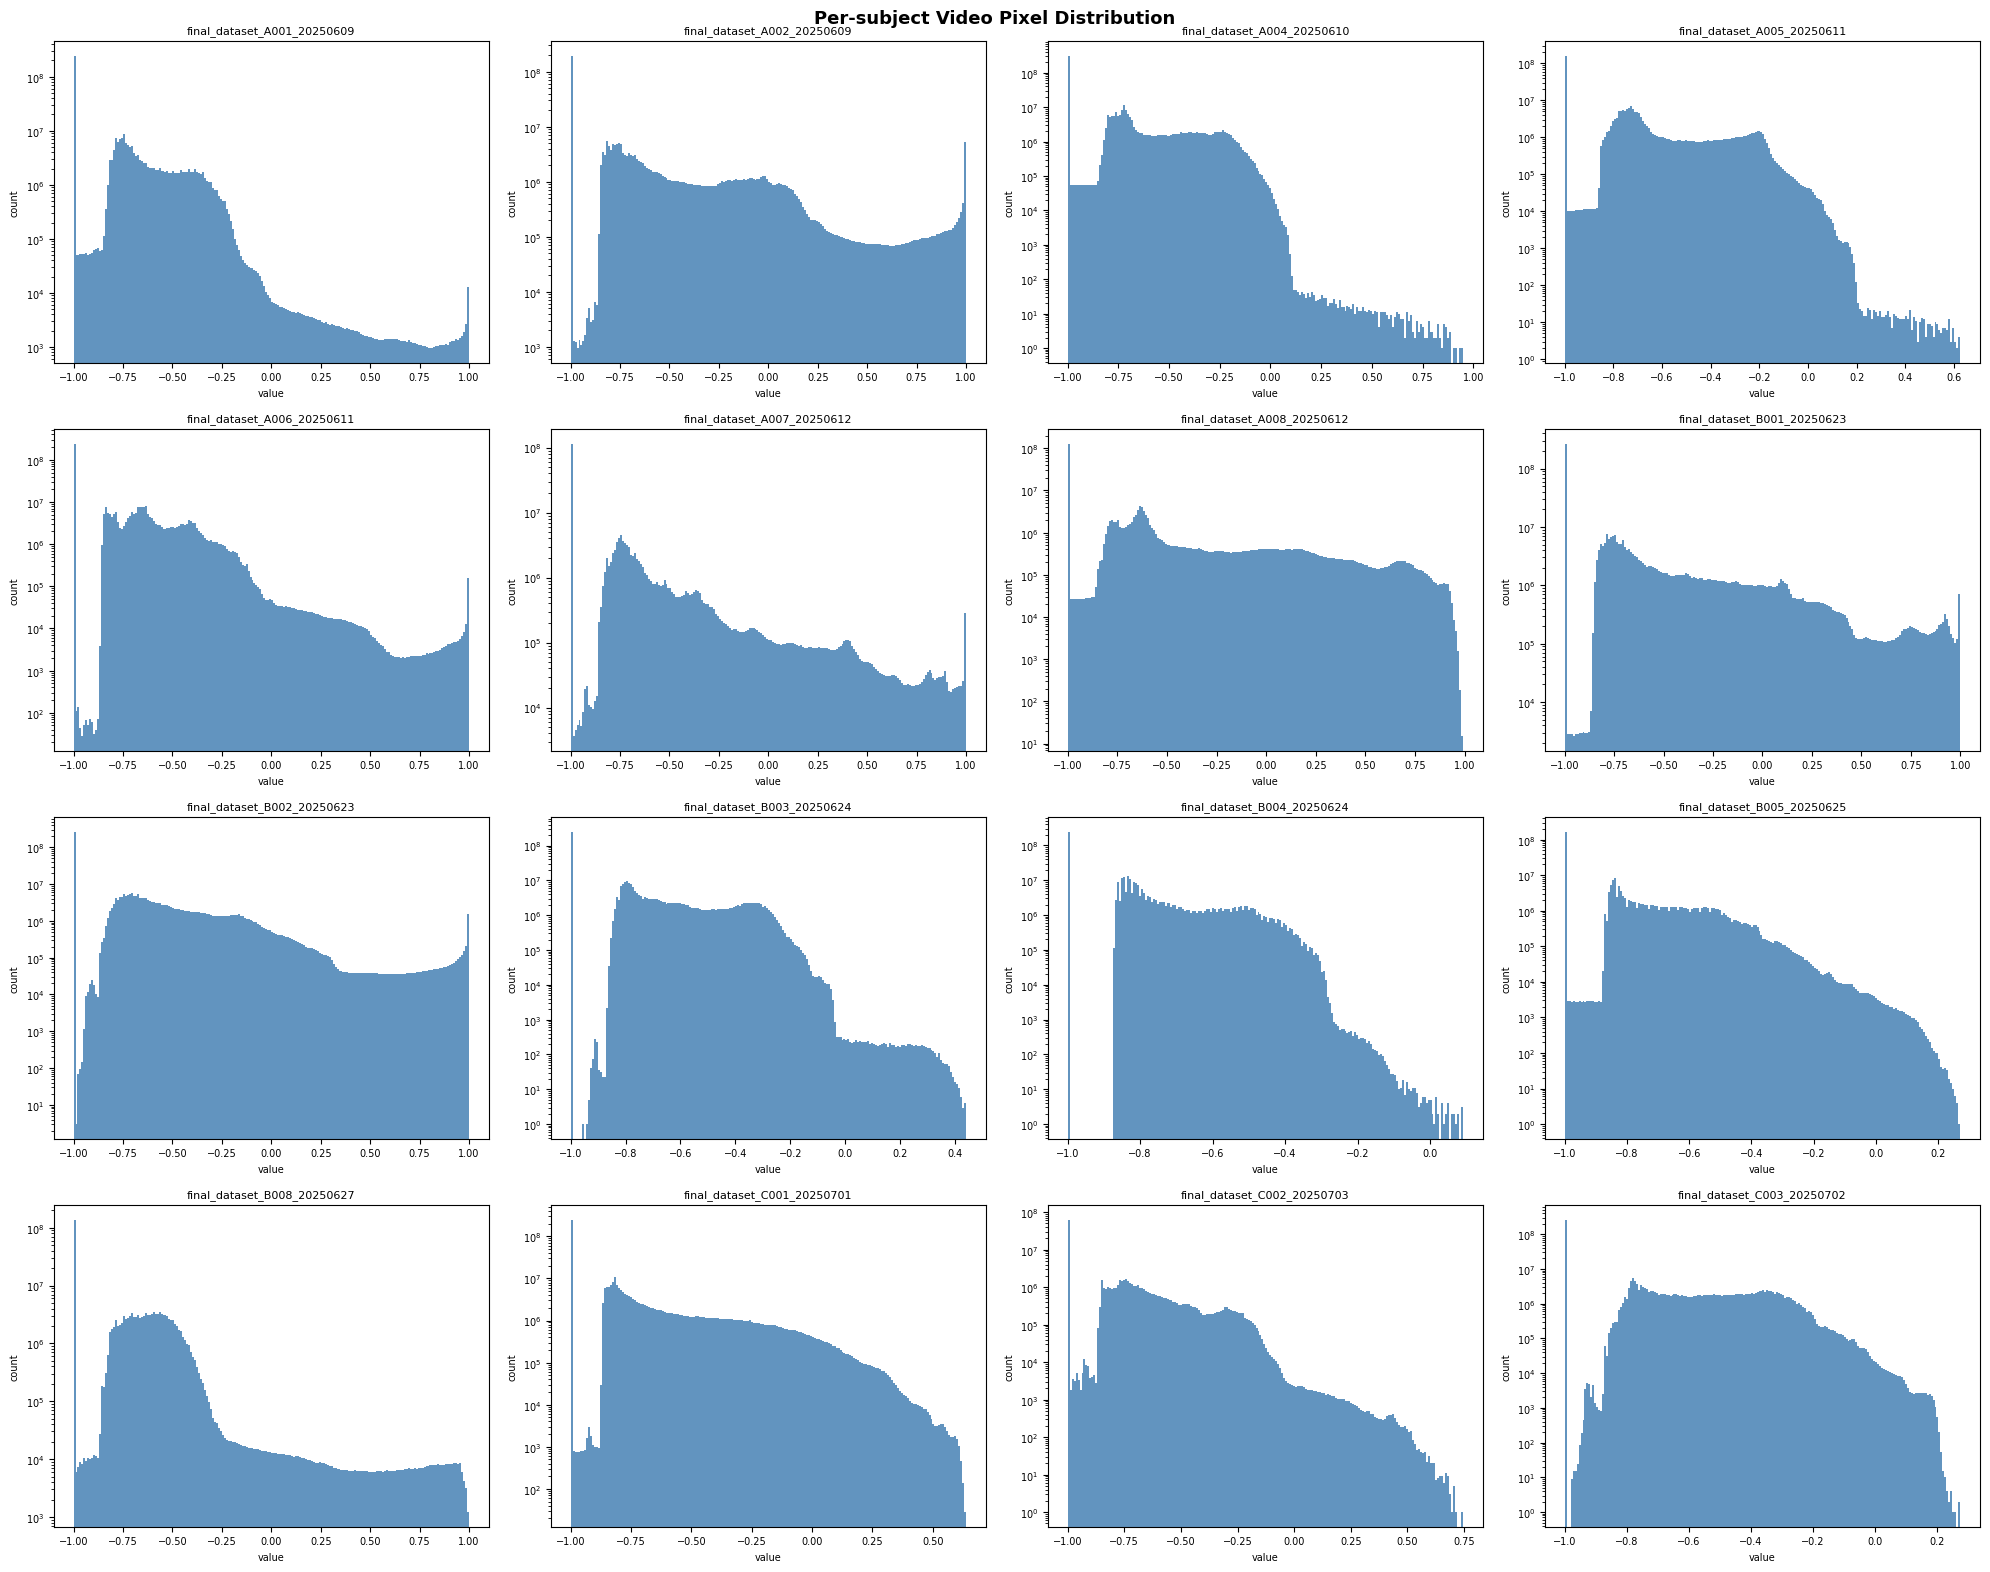

In [9]:
import os
import h5py
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

H5_DIR   = '/home/son/orientation-uv-rppg/video_link/CNA_members/KM_preprocess_data/dl_data_CNA_70_withoutoutlier'
SAVE_DIR = os.path.join('/home/son/orientation-uv-rppg/data/pics', 'histogram_plots')
os.makedirs(SAVE_DIR, exist_ok=True)

h5_files = sorted(Path(H5_DIR).glob('*.h5'))
n = len(h5_files)
ncols = 4
nrows = (n + ncols - 1) // ncols

fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows))
axes = axes.ravel()

for i, h5_path in enumerate(h5_files):
    with h5py.File(str(h5_path), 'r') as f:
        flat = f['video'][:].ravel().astype(np.float32)
        flat = (flat -0.5) / 0.5

    axes[i].hist(flat, bins=200, color='steelblue', alpha=0.85, log = True)
    #axes[i].axvline( 3.0, color='red',    lw=1.2, ls='--')
    #axes[i].axvline(-3.0, color='orange', lw=1.2, ls='--')
    axes[i].set_title(h5_path.stem.replace('_windowed', ''), fontsize=8)
    axes[i].set_xlabel('value', fontsize=7)
    axes[i].set_ylabel('count', fontsize=7)
    axes[i].tick_params(labelsize=7)
    print(f"{h5_path.stem}  mean={flat.mean():.3f}  std={flat.std():.3f}  min={flat.min():.3f}  max={flat.max():.3f}")

# 남은 axes 숨기기
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Per-subject Video Pixel Distribution', fontsize=13, fontweight='bold')
plt.tight_layout()
save_path = os.path.join(SAVE_DIR, 'per_subject_histogram.png')
plt.savefig(save_path, dpi=150, bbox_inches='tight')
print(f'\n저장: {save_path}')

In [8]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
import os
import glob

PATH_A = "/home/son/orientation-uv-rppg/video_link/CNA_members/KM_preprocess_data/dl_data_CNA_70_withoutoutlier_len300_gtsubjectznorm"
PATH_B = "/home/son/orientation-uv-rppg/video_link/CNA_members/KM_preprocess_data/dl_data_CNA_70_withoutoutlier_len300"

files_a = sorted(glob.glob(os.path.join(PATH_A, "*.h5")))
files_b = sorted(glob.glob(os.path.join(PATH_B, "*.h5")))

print(f"[A] {len(files_a)} files | [B] {len(files_b)} files")

# 공통 파일명 기준으로 매칭
names_a = {os.path.basename(f): f for f in files_a}
names_b = {os.path.basename(f): f for f in files_b}
common = sorted(set(names_a.keys()) & set(names_b.keys()))
print(f"공통 파일 수: {len(common)}")

if not common:
    print("공통 파일이 없습니다. 파일명을 확인하세요.")
    print("A 샘플:", list(names_a.keys())[:5])
    print("B 샘플:", list(names_b.keys())[:5])
    exit()

# 플롯할 파일 수 (최대 6개)
n_plot = min(6, len(common))
fig, axes = plt.subplots(n_plot, 1, figsize=(16, 3 * n_plot))
if n_plot == 1:
    axes = [axes]

for i, fname in enumerate(common[:n_plot]):
    with h5py.File(names_a[fname], 'r') as fa:
        ppg_a = fa['gt_ppg'][:][0]
    with h5py.File(names_b[fname], 'r') as fb:
        ppg_b = fb['gt_ppg'][:][0]

    ax = axes[i]
    t_a = np.arange(len(ppg_a))
    t_b = np.arange(len(ppg_b))

    ax.plot(t_b, ppg_b, color='steelblue', alpha=0.8, linewidth=0.8, label='B: original')
    ax.plot(t_a, ppg_a, color='tomato', alpha=0.8, linewidth=0.8, label='A: gtsubjectznorm')
    ax.set_title(fname, fontsize=9)
    ax.set_xlabel("frame")
    ax.set_ylabel("amplitude")
    ax.legend(fontsize=8, loc='upper right')
    ax.grid(True, alpha=0.3)

    print(f"[{fname}] A shape={ppg_a.shape}, mean={ppg_a.mean():.4f}, std={ppg_a.std():.4f} | "
          f"B shape={ppg_b.shape}, mean={ppg_b.mean():.4f}, std={ppg_b.std():.4f}")

plt.suptitle("gt_ppg comparison: gtsubjectznorm (A, red) vs original (B, blue)", fontsize=11)
plt.tight_layout()
save_path = "/home/son/compare_gt_ppg.png"
plt.savefig(save_path, dpi=150, bbox_inches='tight')
print(f"\n저장 완료: {save_path}")
plt.close()

[A] 16 files | [B] 16 files
공통 파일 수: 16
[final_dataset_A001_20250609.h5] A shape=(300,), mean=0.0100, std=1.6149 | B shape=(300,), mean=0.0000, std=0.9999
[final_dataset_A002_20250609.h5] A shape=(300,), mean=-0.1302, std=1.7164 | B shape=(300,), mean=0.0000, std=1.0000
[final_dataset_A004_20250610.h5] A shape=(300,), mean=-0.0102, std=0.6899 | B shape=(300,), mean=0.0000, std=0.9999
[final_dataset_A005_20250611.h5] A shape=(300,), mean=-0.0136, std=1.1328 | B shape=(300,), mean=-0.0000, std=1.0000
[final_dataset_A006_20250611.h5] A shape=(300,), mean=-0.0417, std=0.8955 | B shape=(300,), mean=-0.0000, std=0.9999
[final_dataset_A007_20250612.h5] A shape=(300,), mean=-0.0094, std=0.6932 | B shape=(300,), mean=-0.0000, std=0.9999

저장 완료: /home/son/compare_gt_ppg.png


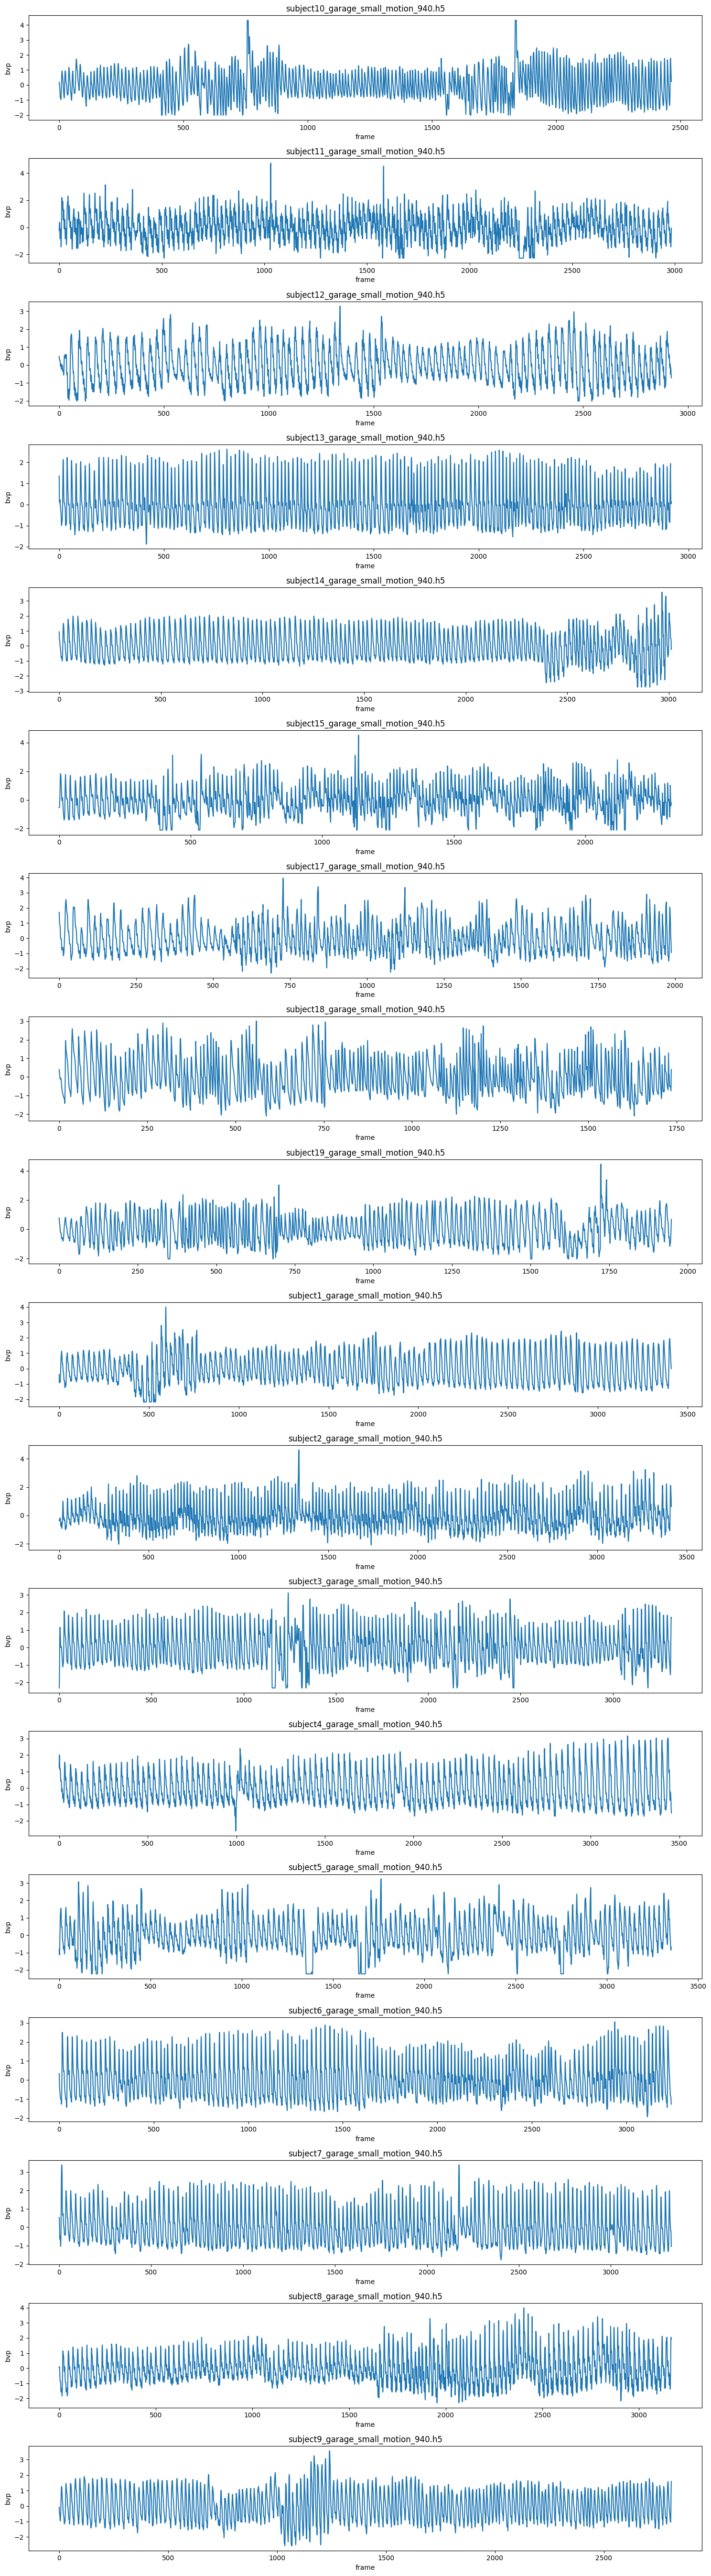

저장완료: bvp_all_subjects.png


In [6]:
# gt ppg 파형확인
import h5py
import os
import matplotlib.pyplot as plt


def bandpass_fft_soft_np(x, fs=30, low_hz=0.66, high_hz = 2.5, steepness=50.0):
    N = x.shape[-1]
    freqs = np.fft.rfftfreq(N, d=1.0/fs)
    fft_x = np.fft.rfft(x)
    mask = (1 / (1 + np.exp(-steepness * (freqs - low_hz)))) * \
           (1 / (1 + np.exp(-steepness * (high_hz - freqs))))
    return np.fft.irfft(fft_x * mask, n=N)


h5_dir = '/nasdata4/2yhy/rPPG_code/rPPG_datasets/h5_data/MR-NIRP_driving_motion'
files = sorted([f for f in os.listdir(h5_dir) if f.endswith('garage_small_motion_940.h5')])

fig, axes = plt.subplots(len(files), 1, figsize=(15, 3*len(files)))

for i, subject in enumerate(files):
    with h5py.File(os.path.join(h5_dir, subject), 'r') as f:
        bvp =f['bvp_data'][:]
    #bvp_bandpass = butter_bandpass_filter(bvp)

    axes[i].plot(bvp)
    #axes[i].plot(bvp_bandpass, color = 'red')
    axes[i].set_title(subject)
    #axes[i].set_xlim(0, 1000)
    axes[i].set_xlabel('frame')
    axes[i].set_ylabel('bvp')

plt.tight_layout()
plt.show()
print("저장완료: bvp_all_subjects.png")

In [141]:
import h5py
import os
import numpy as np

src_dir = '/home/son/orientation-uv-rppg/video_link/CNA_members/KM_preprocess_data/dl_data_CNA_without_registration_cropped'
dst_dir = '/home/son/orientation-uv-rppg/video_link/CNA_members/KM_preprocess_data/dl_data_CNA_70_withoutoutlier'

src_files = sorted([f for f in os.listdir(src_dir) if f.endswith('.h5')])
dst_files = sorted([f for f in os.listdir(dst_dir) if f.endswith('.h5')])

print(f"src 파일 수: {len(src_files)}")
print(f"dst 파일 수: {len(dst_files)}")

for sf, df in zip(src_files, dst_files):
    print(f"\n{df} ← {sf}")

    with h5py.File(os.path.join(src_dir, sf), 'r') as f_src:
        gt_src = f_src['gt_ppg'][:]
    
    with h5py.File(os.path.join(dst_dir, df), 'r') as f_dst:
        gt_dst = f_dst['gt_ppg'][:]
    
    print(f"  src shape: {gt_src.shape}, dst shape: {gt_dst.shape}")

    if gt_src.shape[0] != gt_dst.shape[0]:
        print(f"  ⚠️ window 수 불일치! skip")
        continue

    with h5py.File(os.path.join(dst_dir, df), 'a') as f_dst:
        del f_dst['gt_ppg']
        f_dst.create_dataset('gt_ppg', data=gt_src, chunks=True, compression='gzip', compression_opts=4)
    
    print(f"  ✅ 덮어쓰기 완료")

src 파일 수: 16
dst 파일 수: 16

final_dataset_A001_20250609.h5 ← dataset_wo_registration_cropped_A001_20250609.h5
  src shape: (108, 900), dst shape: (108, 900)
  ✅ 덮어쓰기 완료

final_dataset_A002_20250609.h5 ← dataset_wo_registration_cropped_A002_20250609.h5
  src shape: (100, 900), dst shape: (100, 900)
  ✅ 덮어쓰기 완료

final_dataset_A004_20250610.h5 ← dataset_wo_registration_cropped_A004_20250610.h5
  src shape: (134, 900), dst shape: (134, 900)
  ✅ 덮어쓰기 완료

final_dataset_A005_20250611.h5 ← dataset_wo_registration_cropped_A005_20250611.h5
  src shape: (84, 900), dst shape: (84, 900)
  ✅ 덮어쓰기 완료

final_dataset_A006_20250611.h5 ← dataset_wo_registration_cropped_A006_20250611.h5
  src shape: (125, 900), dst shape: (125, 900)
  ✅ 덮어쓰기 완료

final_dataset_A007_20250612.h5 ← dataset_wo_registration_cropped_A007_20250612.h5
  src shape: (54, 900), dst shape: (54, 900)
  ✅ 덮어쓰기 완료

final_dataset_A008_20250612.h5 ← dataset_wo_registration_cropped_A008_20250612.h5
  src shape: (61, 900), dst shape: (61, 900

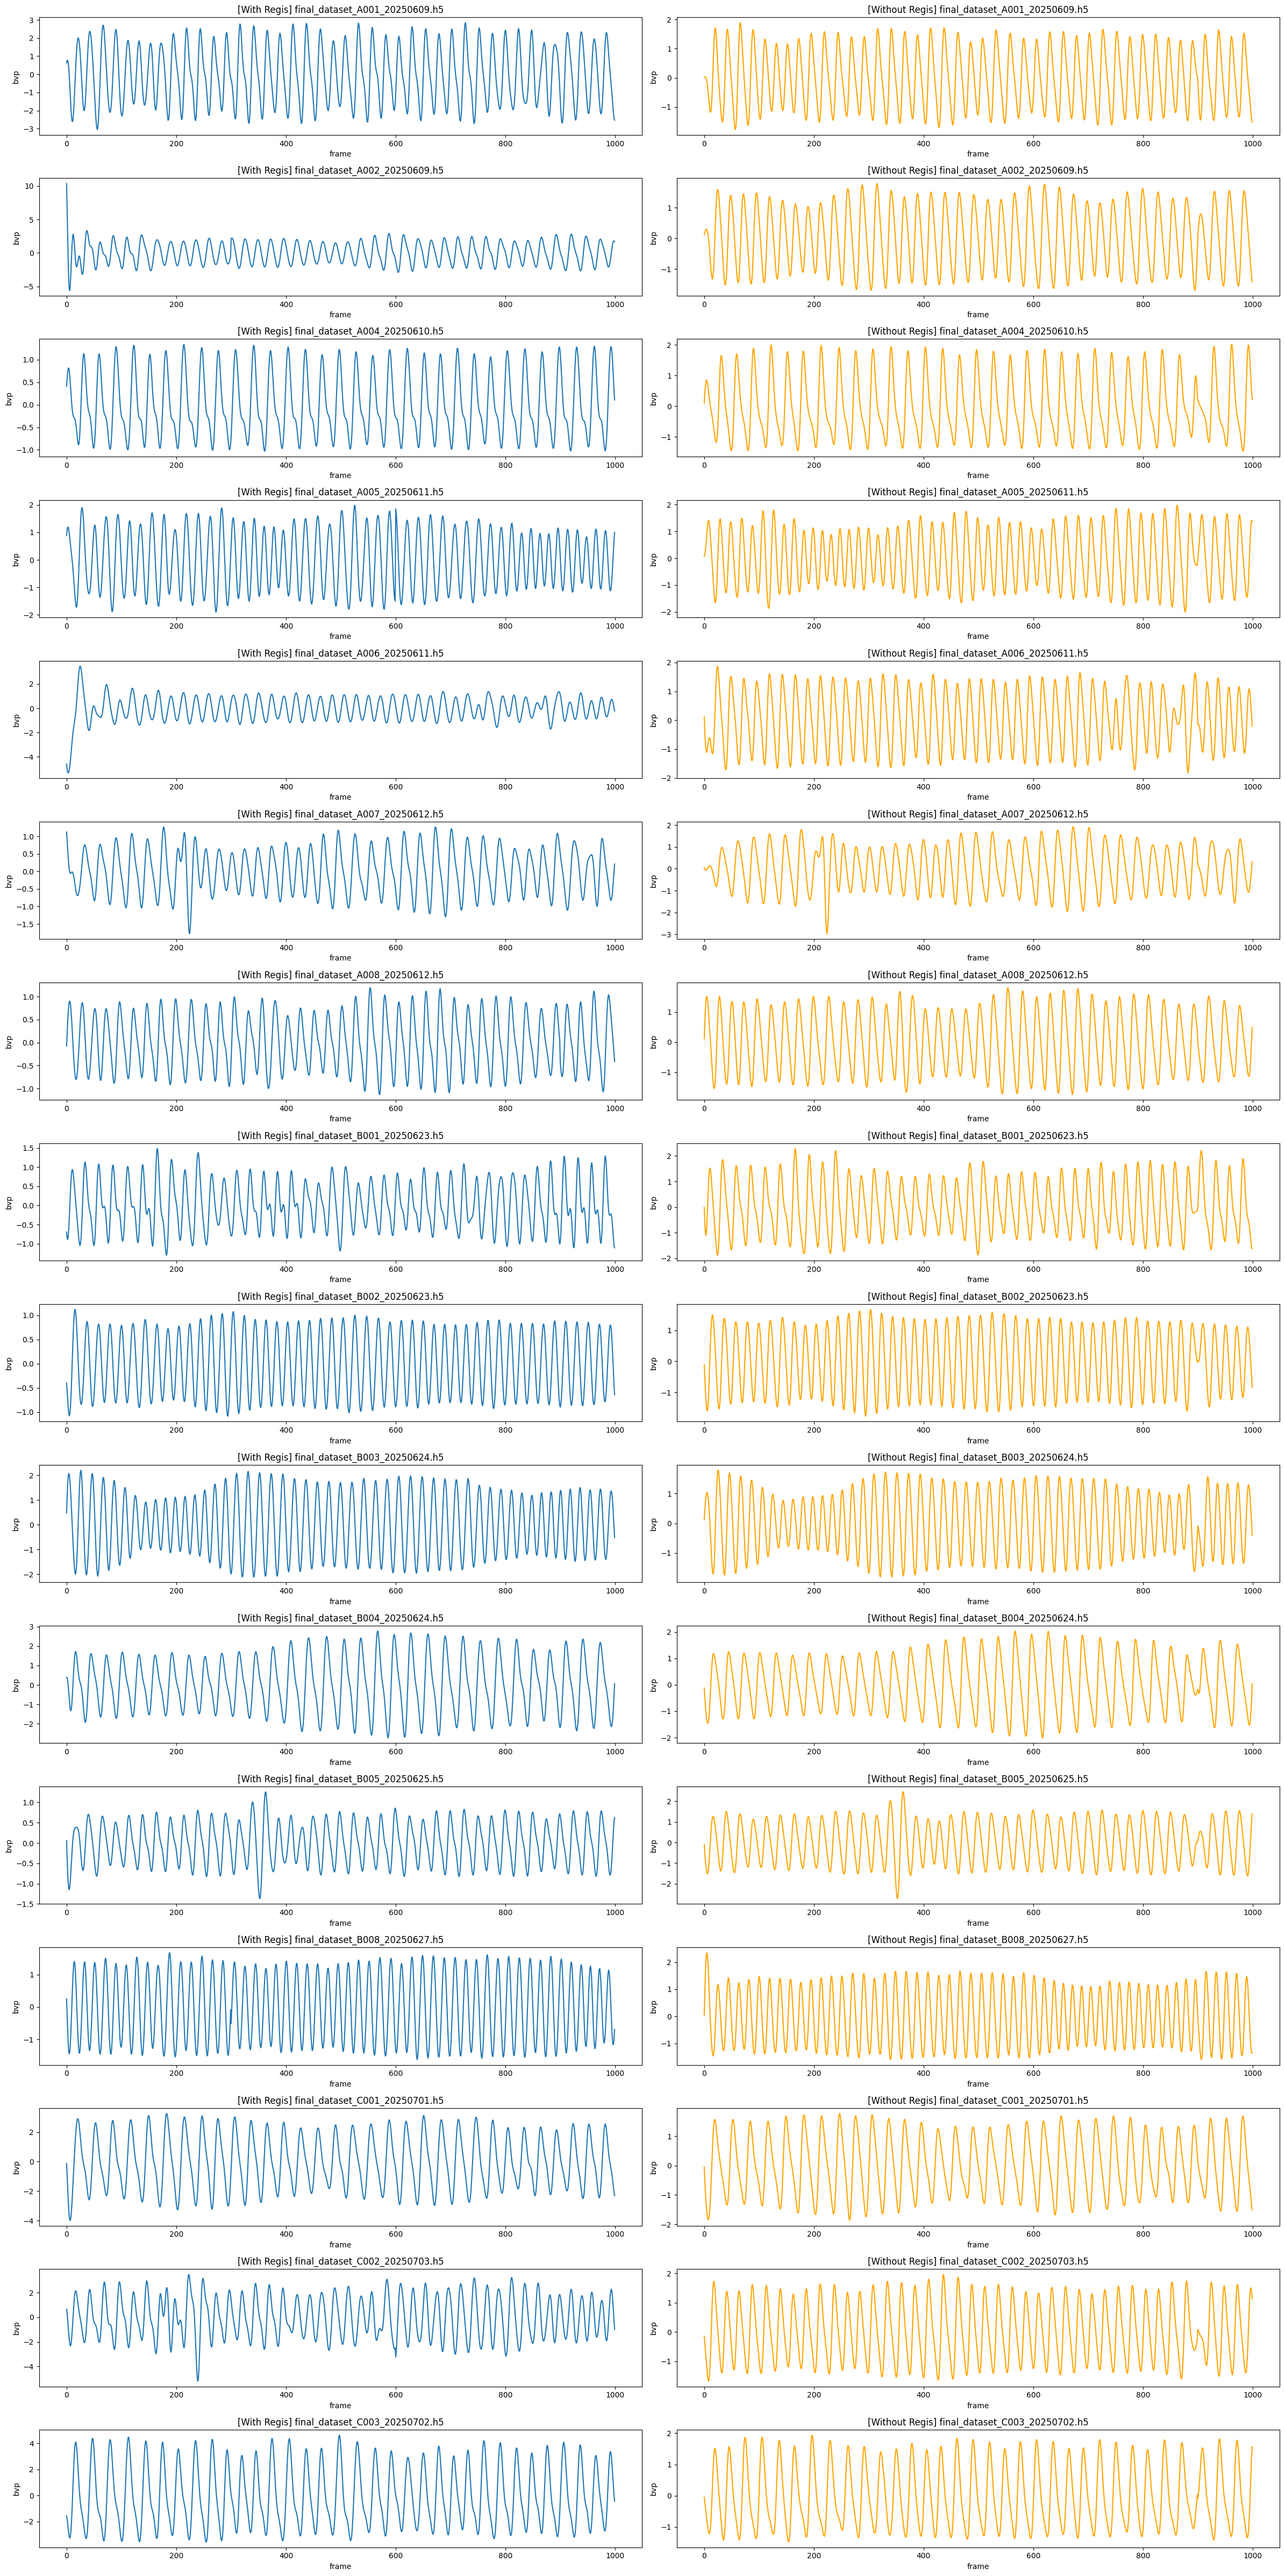

저장완료: bvp_all_subjects_comparison.png


In [171]:
import h5py
import os
import numpy as np
import matplotlib.pyplot as plt

def z_norm(data):
    return (data - np.mean(data, axis=0)) / (np.std(data, axis=0) + 1e-8)

h5_dir_regis = '/home/son/orientation-uv-rppg/video_link/CNA_members/KM_preprocess_data/dl_data_CNA_without_registration_cropped_len300'
h5_dir_noreg = '/home/son/orientation-uv-rppg/video_link/CNA_members/KM_preprocess_data/dl_data_CNA_70_withoutoutlier'

files_regis = sorted([f for f in os.listdir(h5_dir_regis) if f.endswith('.h5')])
files_noreg = sorted([f for f in os.listdir(h5_dir_noreg) if f.endswith('.h5')])

n_subjects = max(len(files_regis), len(files_noreg))
fig, axes = plt.subplots(n_subjects, 2, figsize=(24, 3 * n_subjects))

for i in range(n_subjects):
    # 왼쪽: registration 적용
    if i < len(files_regis):
        with h5py.File(os.path.join(h5_dir_regis, files_regis[i]), 'r') as f:
            bvp = np.concatenate(f['gt_ppg'][:], axis=0)[:1000]
        axes[i, 0].plot(bvp)
        axes[i, 0].set_title(f'[With Regis] {files_regis[i]}')
    else : 
        axes[i, 0].set_visible(False)

    # 오른쪽: registration 미적용
    if i < len(files_noreg):
        with h5py.File(os.path.join(h5_dir_noreg, files_noreg[i]), 'r') as f:
            bvp = np.concatenate(f['gt_ppg'][:], axis=0)[:1000]
        axes[i, 1].plot(bvp, color='orange')
        axes[i, 1].set_title(f'[Without Regis] {files_noreg[i]}')
    else:
        axes[i, 1].set_visible(False)

    for col in range(2):
        if axes[i, col].get_visible():
            axes[i, col].set_xlabel('frame')
            axes[i, col].set_ylabel('bvp')

plt.tight_layout()
plt.savefig('bvp_all_subjects_comparison.png', dpi=150)
plt.show()
print("저장완료: bvp_all_subjects_comparison.png")

final_dataset_A007_20250612.h5
video.shape: (54, 900, 64, 64)
video.dtype: float64
max value of frame 0: 0.9686450958251953


TypeError: Invalid shape (900, 64, 64) for image data

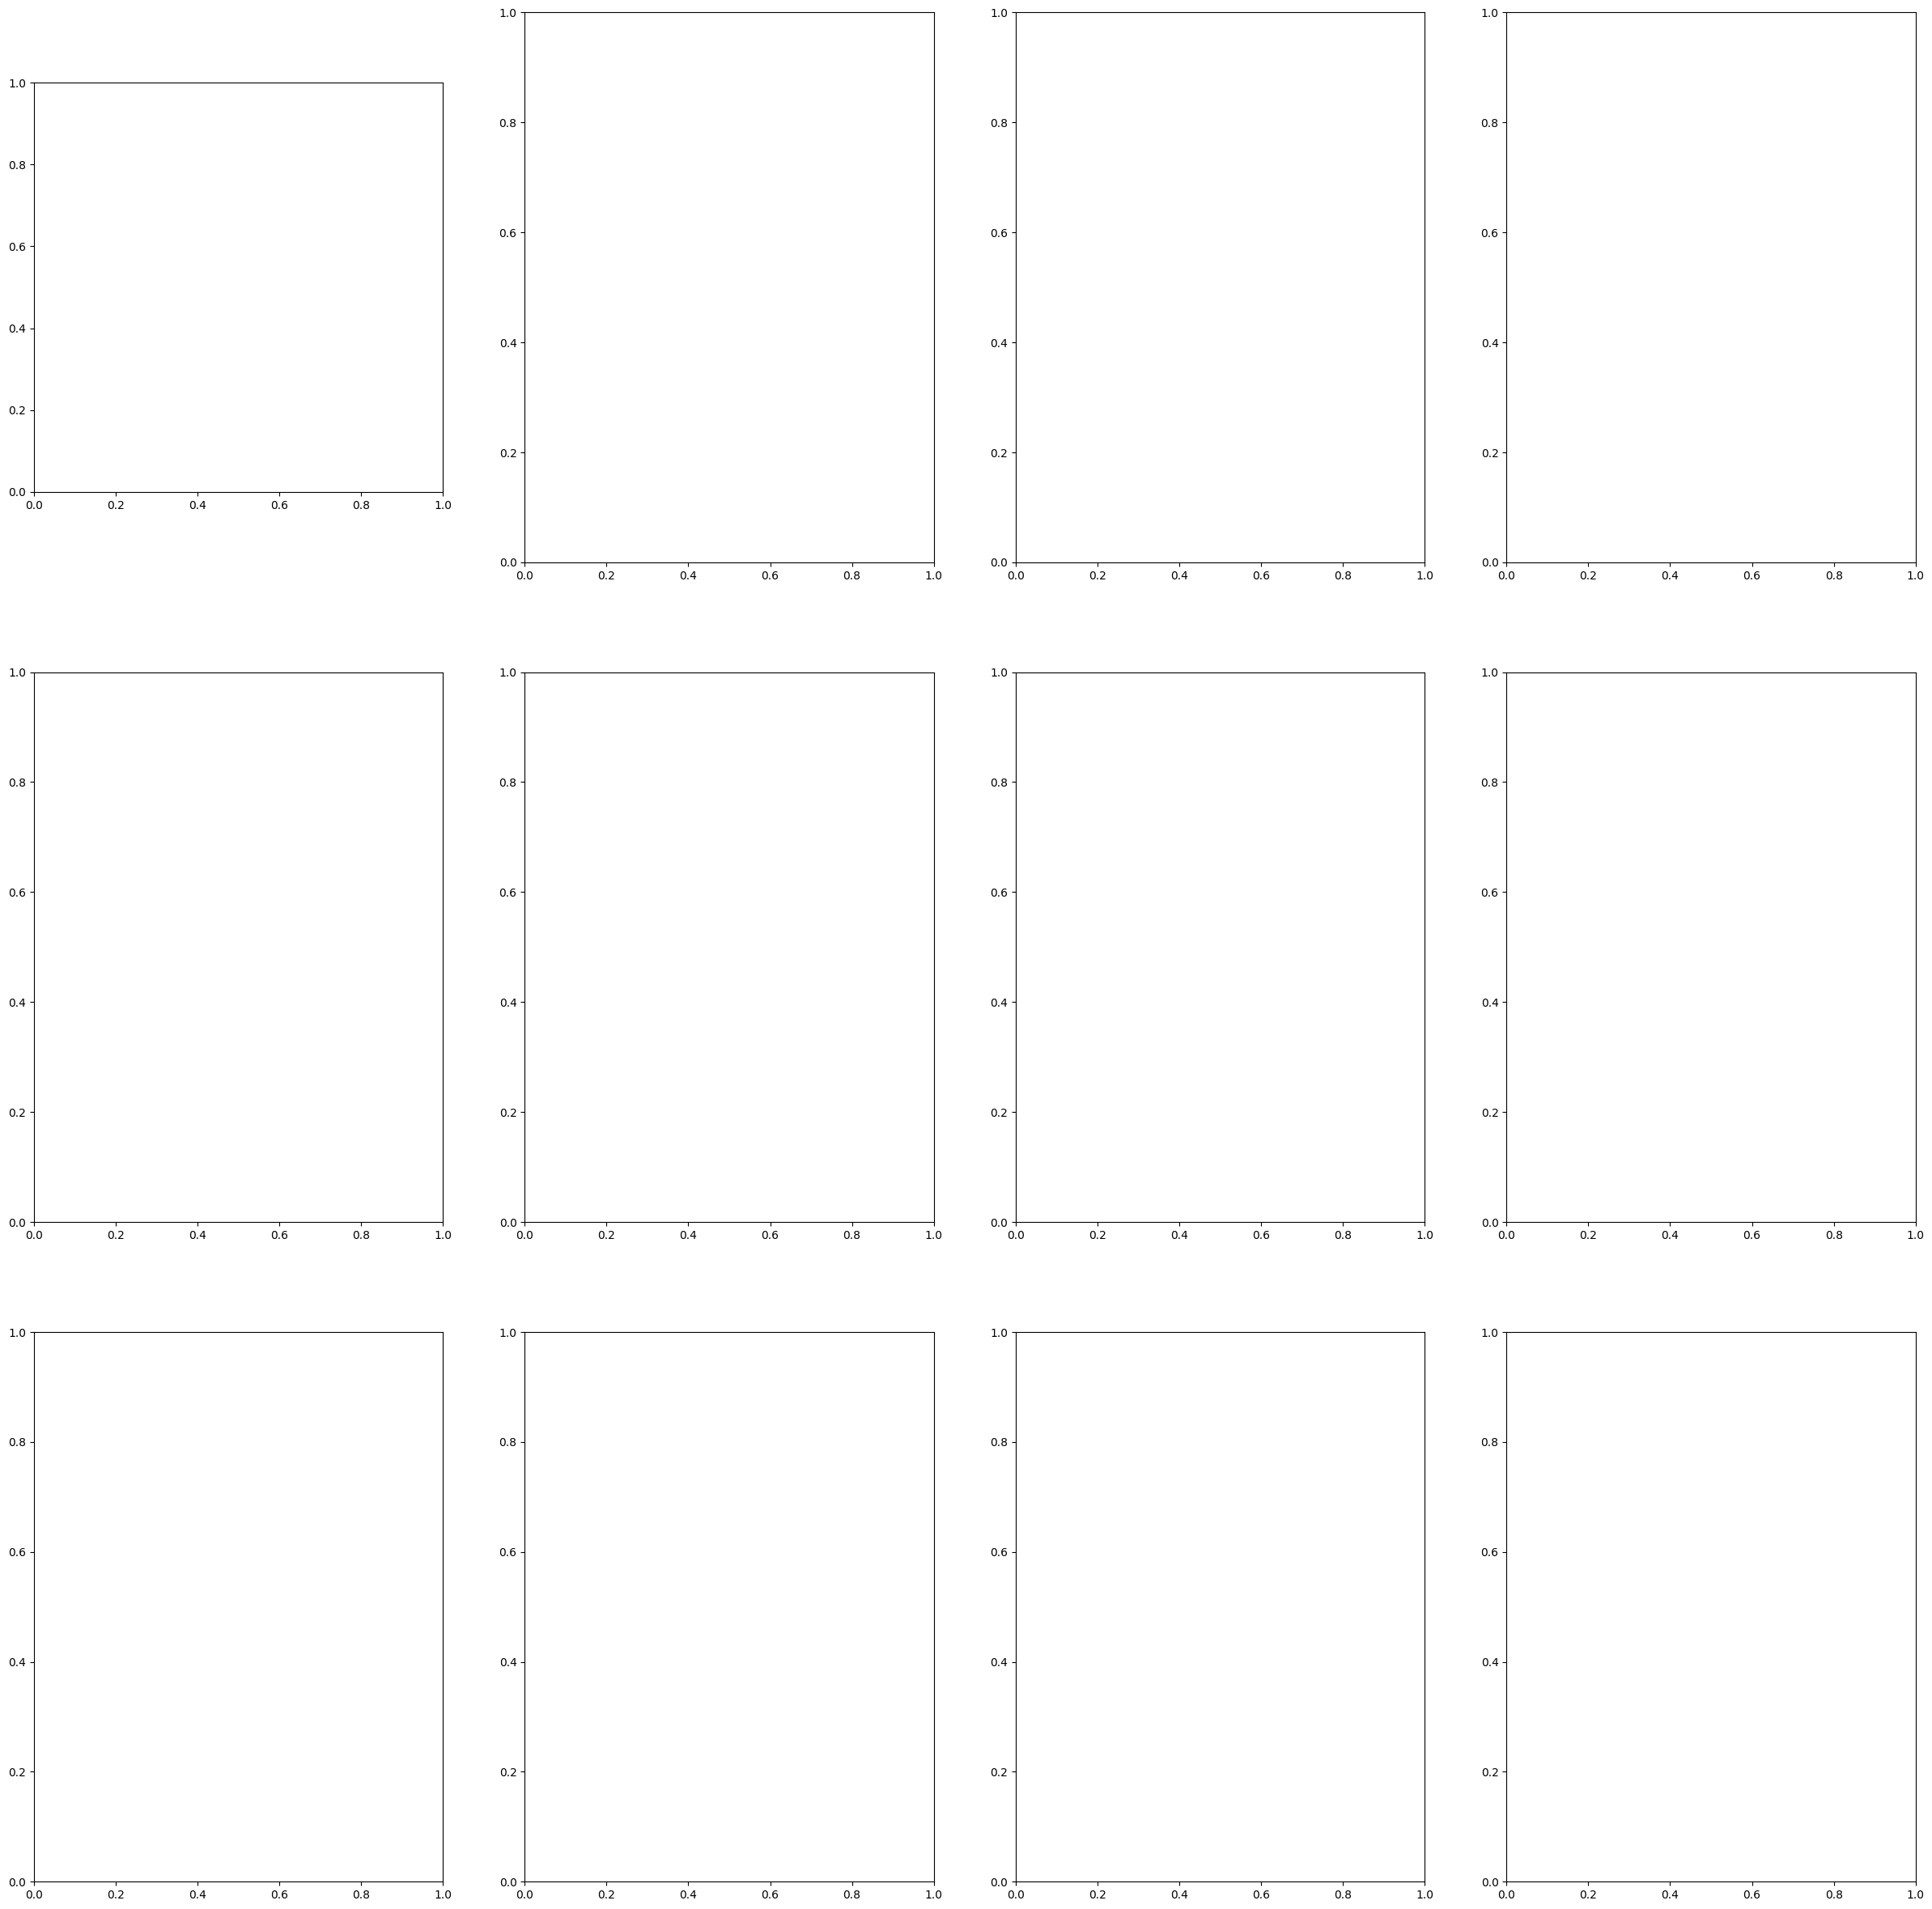

In [19]:
# 원본영상확인
id = 5
h5_dir = '/home/son/orientation-uv-rppg/video_link/CNA_members/KM_preprocess_data/dl_data_CNA_70_withoutoutlier'
files = sorted([f for f in os.listdir(h5_dir) if f.endswith('h5')])
print(files[id])
with h5py.File(os.path.join(h5_dir, files[id]), 'r') as f:
    video = f['video'][:]
print('video.shape:', video.shape)
print('video.dtype:', video.dtype)

# 비디오 사진 확인 - 앞에서 12프레임
fig, axes = plt.subplots(3, 4, figsize=(30, 30))
axes = axes.flatten()
for i in range(12):
    axes[i].imshow(video[i], cmap='gray')
    axes[i].set_title(f'frame num : {i}')
plt.tight_layout()
plt.show()

subject11_garage_small_motion_975_uv.h5
(3066, 128, 128)
float32


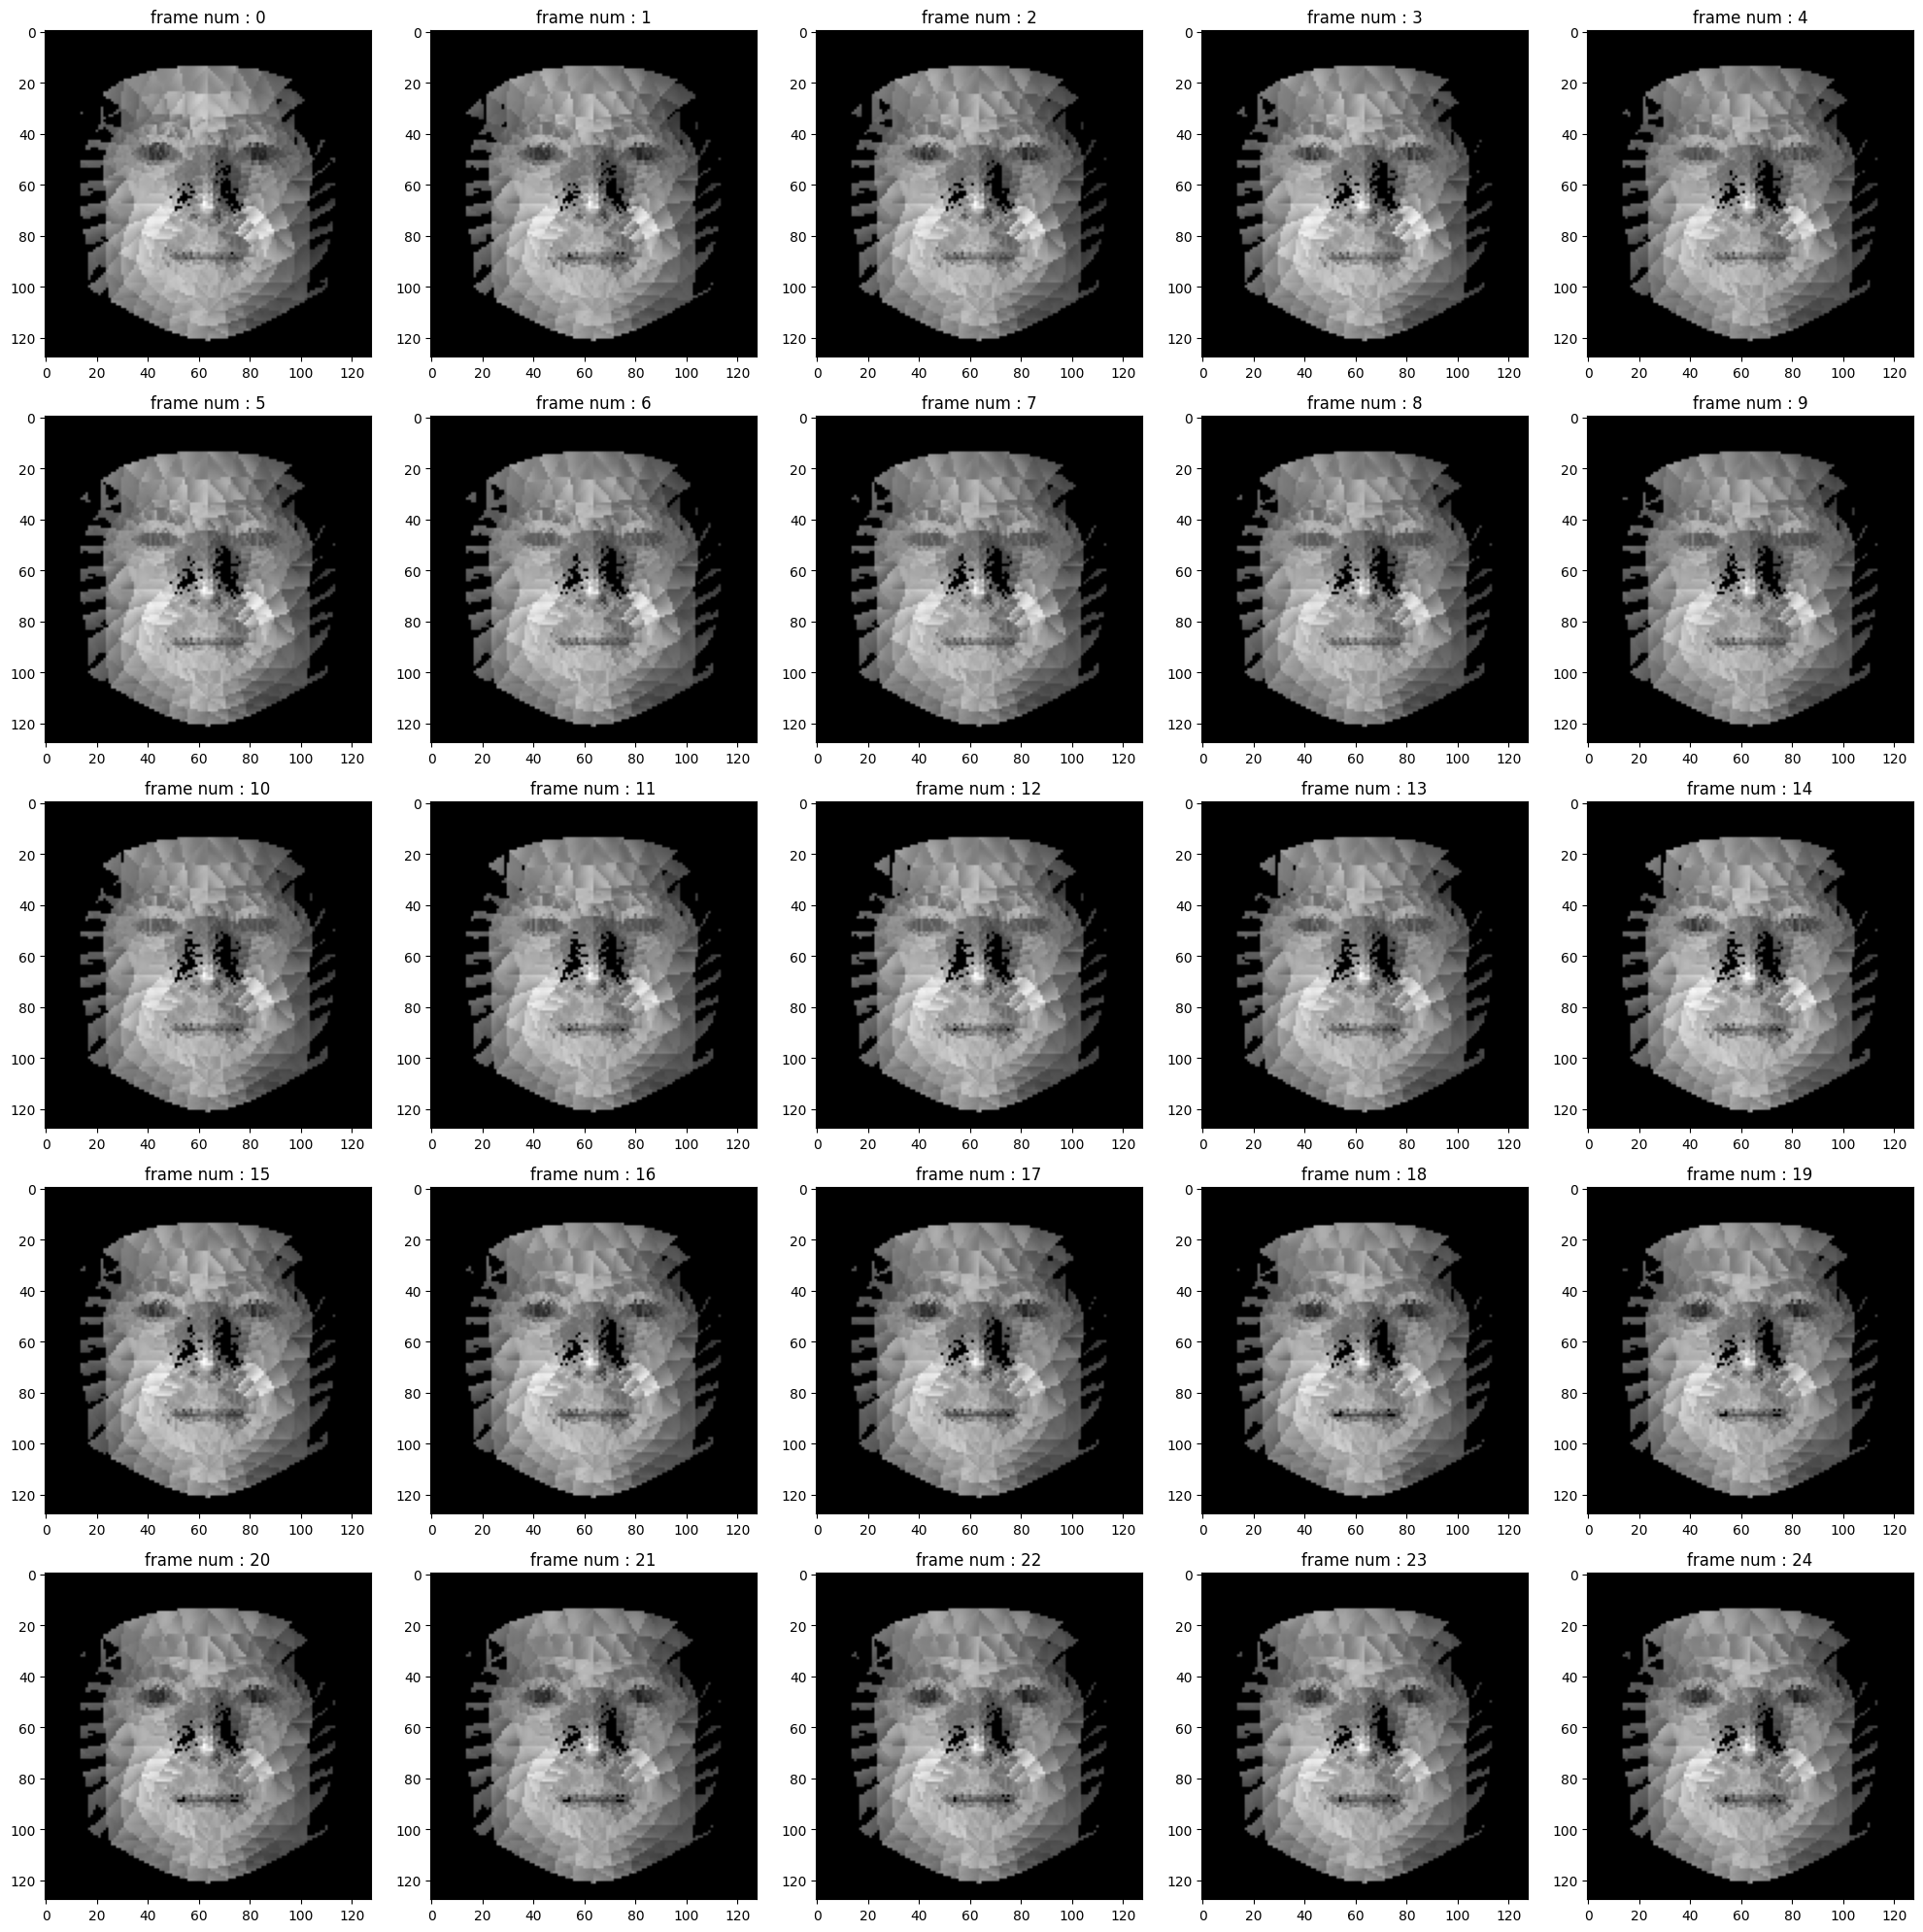

In [38]:
#registration 결과 확인
regist_dir ='/home/son/orientation-uv-rppg/video_link/CNA_members/KM_preprocess_data/MR-nirp_driving_motion_registration'
people = sorted(os.listdir(regist_dir))

id = 11
print(people[id])
with h5py.File(os.path.join(regist_dir, people[id]), 'r') as f:
    video = f['nir_uv_data'][:]

print(video.shape)
print(video.dtype)


fig, axes = plt.subplots(5,5, figsize = (20,20))
axes = axes.flatten()
for i, im in enumerate(video[:25]) :

    axes[i].imshow(im, cmap ='gray')
    axes[i].set_title(f'frame num : {i}')

plt.tight_layout()
plt.show()

subject5_garage_large_motion_975_dldata.h5
(11, 300, 64, 64)
float32


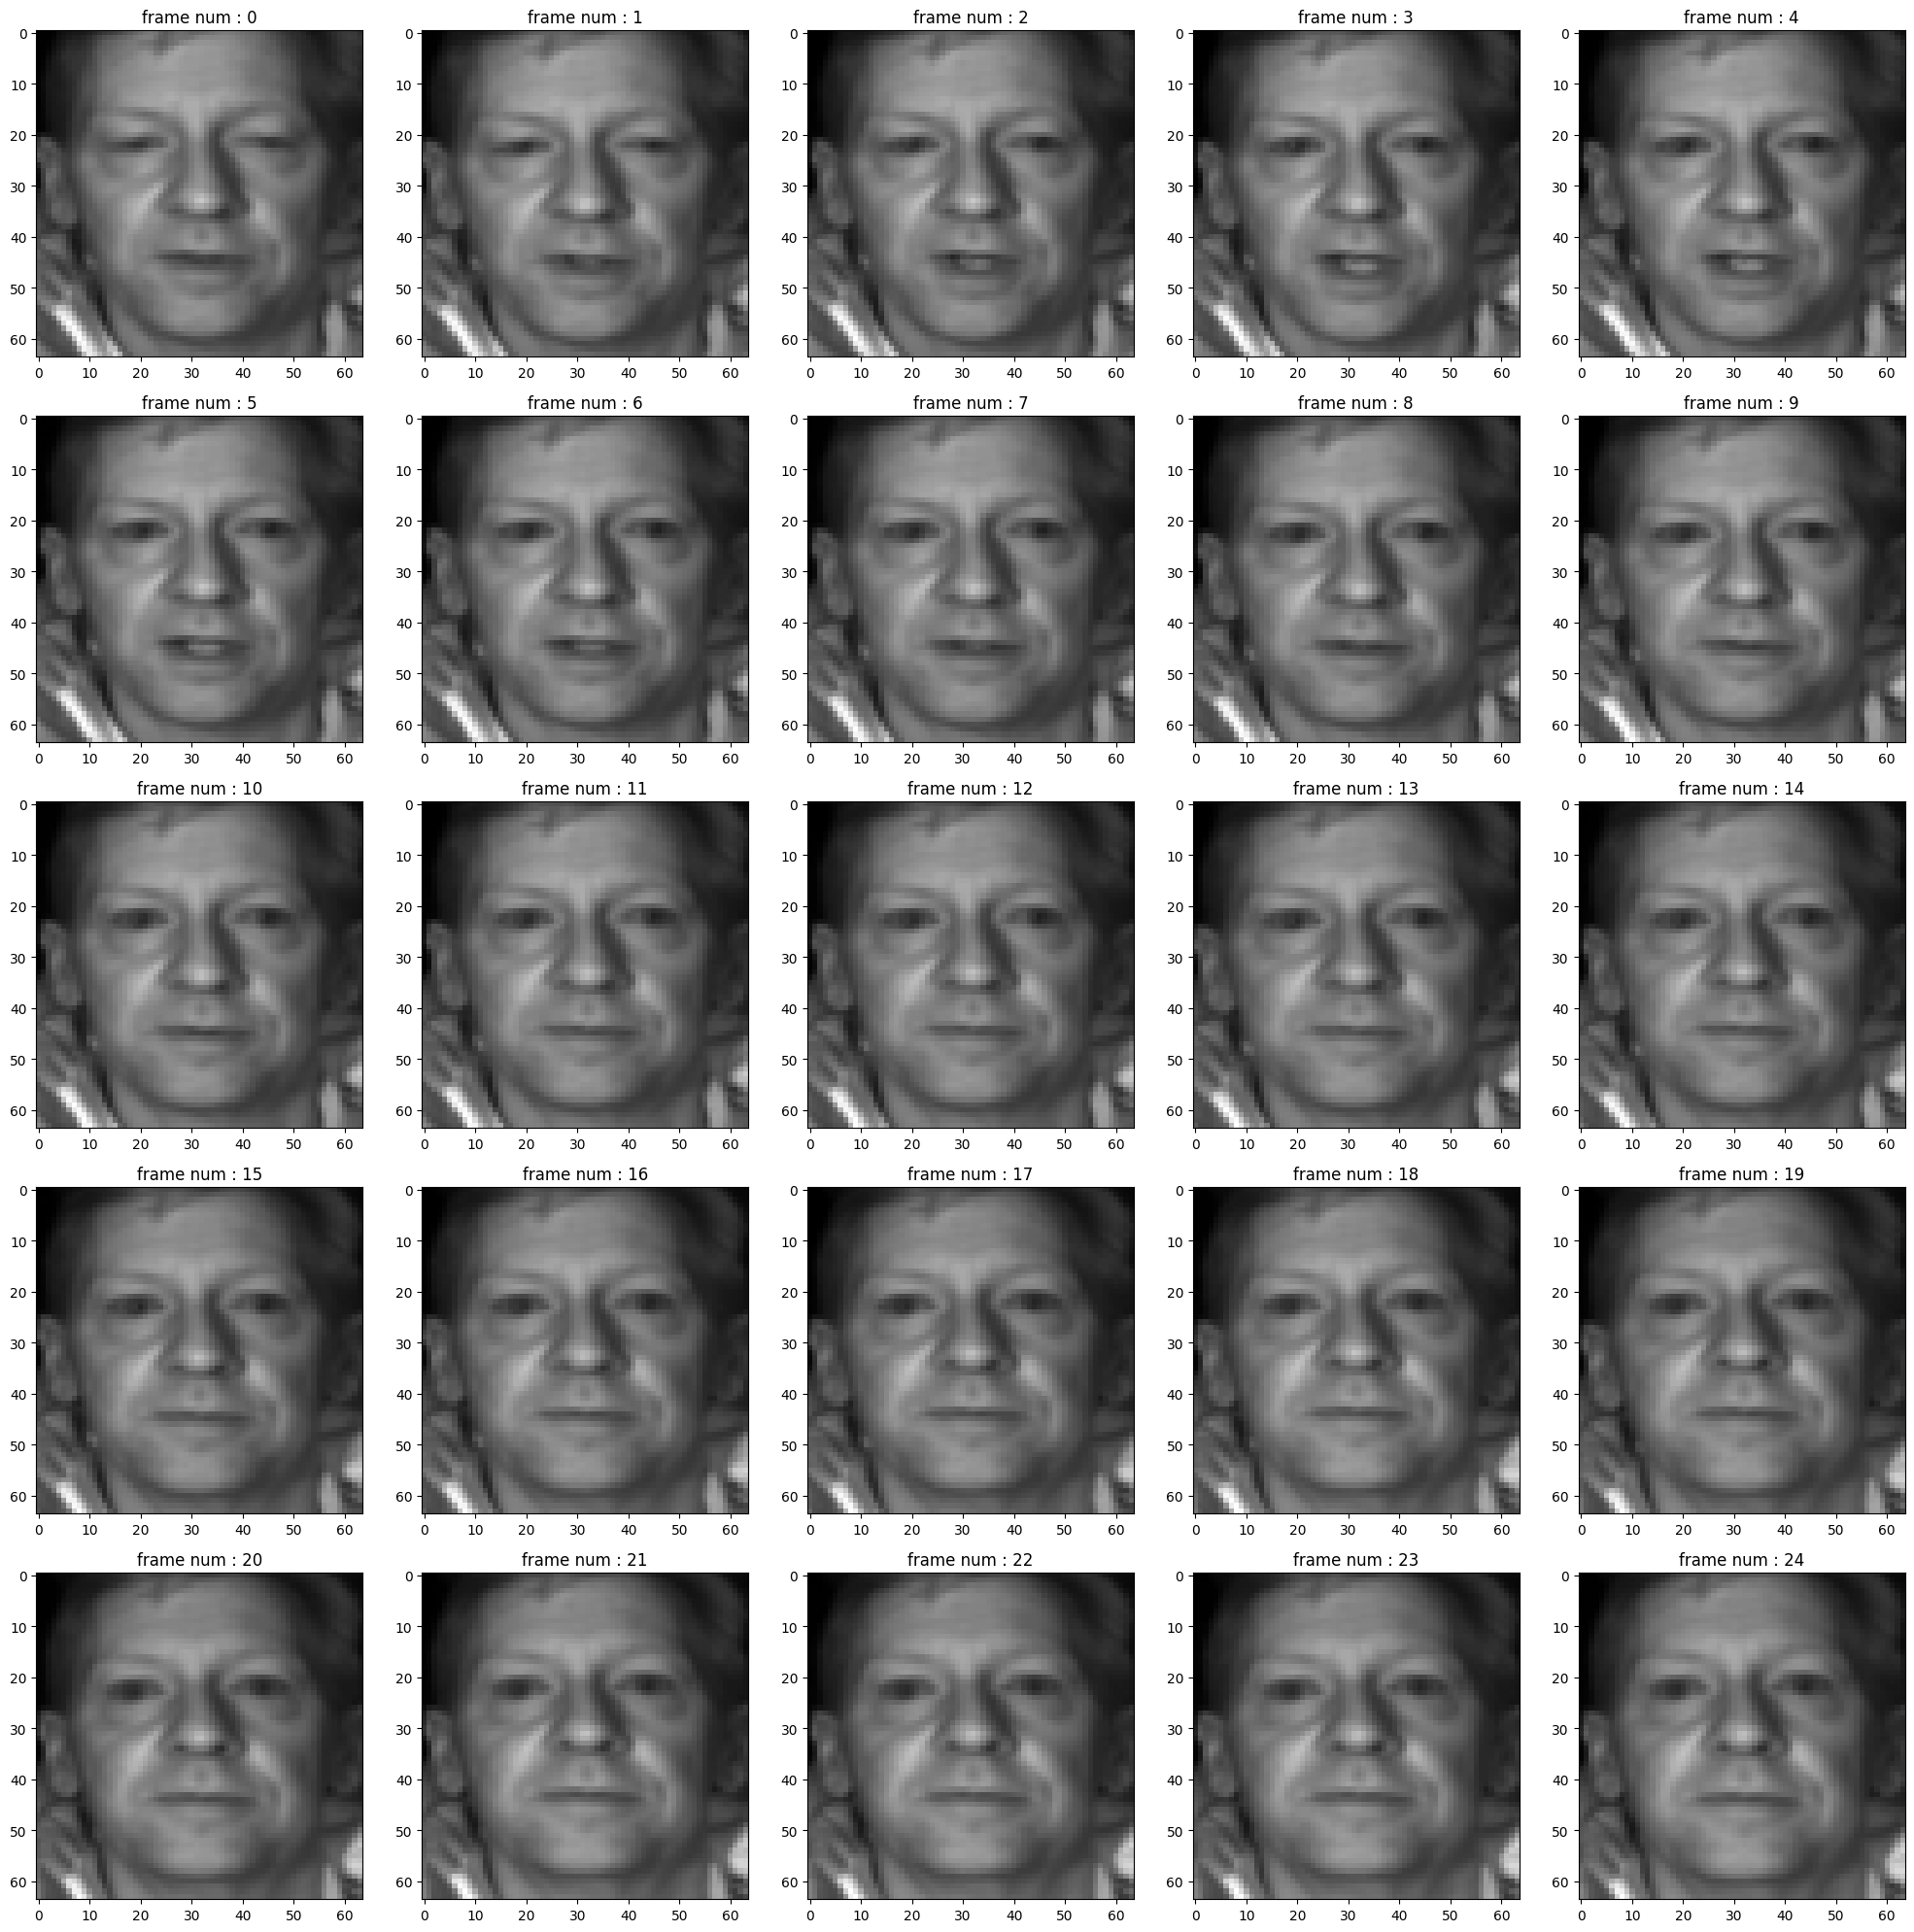

In [41]:
#dl_data 확인
regist_dir ='/home/son/orientation-uv-rppg/video_link/CNA_members/KM_preprocess_data/driving_cropped_dl_data'
people = sorted(os.listdir(regist_dir))

id = 11
print(people[id])
with h5py.File(os.path.join(regist_dir, people[id]), 'r') as f:
    video = f['video'][:]

print(video.shape)
print(video.dtype)


fig, axes = plt.subplots(5,5, figsize = (20,20))
axes = axes.flatten()
for i, im in enumerate(video[0][:25]) :

    axes[i].imshow(im, cmap ='gray')
    axes[i].set_title(f'frame num : {i}')

plt.tight_layout()
plt.show()

In [40]:
#dl_data 확인
regist_dir ='/nasdata4/2yhy/rPPG_code/rPPG_datasets/raw_data/CNA_members/KM_preprocess_data/raw_video'
people = sorted(os.listdir(regist_dir))

id = 11
print(people[id])
with h5py.File(os.path.join(regist_dir, people[id]), 'r') as f:
    video = f['video'][:]

print(video.shape)
print(video.dtype)
print(np.max(video))
print(np.min(video))


fig, axes = plt.subplots(5,5, figsize = (20,20))
axes = axes.flatten()
for i, im in enumerate(video[:25]) :

    axes[i].imshow(im, cmap ='gray')
    axes[i].set_title(f'frame num : {i}')

plt.tight_layout()
plt.show()

FileNotFoundError: [Errno 2] No such file or directory: '/nasdata4/2yhy/rPPG_code/rPPG_datasets/raw_data/CNA_members/KM_preprocess_data/raw_video'

In [ ]:
all_sub_list = [i for i in subject_file_map.keys()]

folded_list = np.array_split(all_sub_list, k)
folded_list = [list(k) for k in folded_list]

for i, valid_list in enumerate(folded_list) :
    train_list = [k for k in all_sub_list if k not in valid_list]

    train_ds = [*s for j in train_list for s in subject_file_map[j]]